# ML-03 — Frame Your Lane as an ML Task

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JackTheProgrammer/flyrank-ml-internship-track/blob/main/work/notebooks/w02_ml_task_framing.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. My lane as an ML task (type)

*Classification, clustering, ranking, or scoring — which one, and why?*

The lane which I selected is lane 3: structured content archetype clustering, which is about the question "What performance archetypes exist across the content inventory?", henceforth, the ML task to be deployed here is that of clustering

In [7]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import pandas as pd

raw_data_dir = '../../data/raw/content_refresh_anonymized.csv'

df = pd.read_csv(raw_data_dir)
df

,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.00,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.00,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.00,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.00,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.00,good,page_3_5,down,-34.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,content_c322796023c8,client_e29c9c180c,10.0,0.05,LOW,0.00,keyword article,transactional,1386.0,9084.0,...,8000-15000,0.00,0.0,0.00,0.00,0.00,low,top_3,new,NaN
29996,content_526572edb3fa,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,2654.0,17056.0,...,15000-25000,0.39,6.6,0.00,66.67,0.00,moderate,page_1,down,-75.1
29997,content_38112bdd0c6e,client_349c41201b,10.0,1.00,HIGH,0.00,keyword article,transactional,2857.0,18725.0,...,15000-25000,0.19,4.1,0.00,0.00,0.00,good,page_1,down,-66.2
29998,content_ab26273a7e7a,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,transactional,NaN,NaN,...,NaN,0.22,6.0,1.73,4.06,0.00,excellent,page_1,down,-27.9


## 2. Target or proxy

*What would you predict? Where does that label come from — observed outcome or a defined rule?*

Since it is a clustering problem, so there is no question of label to be predicted. The intention behind this task is to answer the archetypal grouping question of this specific lane, so as per the lane guideline, here is the list of possible archetypes:
* champions;
* rising stars;
* hidden gems;
* stale visible pages;
* weak/no-demand pages;
* engagement-problem pages;
* cannibalization-risk pages.

These are given as the example names, so in my ML crafted clusters, I'll plot them first, run queries upon them in order to find their characteristics and then give them the names accordingly.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Success metric

*One metric you can defend. What number means 'good'?*

The primary mathematical success metric for this unsupervised pipeline will be the **Silhouette** Score, targeting an optimal structural configuration value > `0.5` to confirm dense, well-isolated coordinate groupings. We will supplement this by evaluating the **Davies-Bouldin Index** (seeking minimizing metrics toward 0) and tracking Inertia inflection trends using the **elbow** method.

Algorithms to be deployed:
* **K-Means Clustering:** Deployed alongside PCA to segment hyper-ellipsoidal density boundaries.
* **DBSCAN:** Deployed to discover arbitrary, non-linear geometric shapes and naturally flag low-density outlier noise pages (weak/no-demand pages).

Below is the example code to demonstrate the procedures to be followed, but on the subset of features, and only for the `KMeans` algorithm.

Evaluating cluster metrics across range...
K=2 | Silhouette Score: 0.3033 (Aiming > 0.5) | Davies-Bouldin: 1.3577 (Aiming lower)
K=3 | Silhouette Score: 0.2676 (Aiming > 0.5) | Davies-Bouldin: 1.4004 (Aiming lower)
K=4 | Silhouette Score: 0.2596 (Aiming > 0.5) | Davies-Bouldin: 1.4973 (Aiming lower)
K=5 | Silhouette Score: 0.2544 (Aiming > 0.5) | Davies-Bouldin: 1.3832 (Aiming lower)
K=6 | Silhouette Score: 0.2737 (Aiming > 0.5) | Davies-Bouldin: 1.2796 (Aiming lower)
K=7 | Silhouette Score: 0.2778 (Aiming > 0.5) | Davies-Bouldin: 1.2435 (Aiming lower)


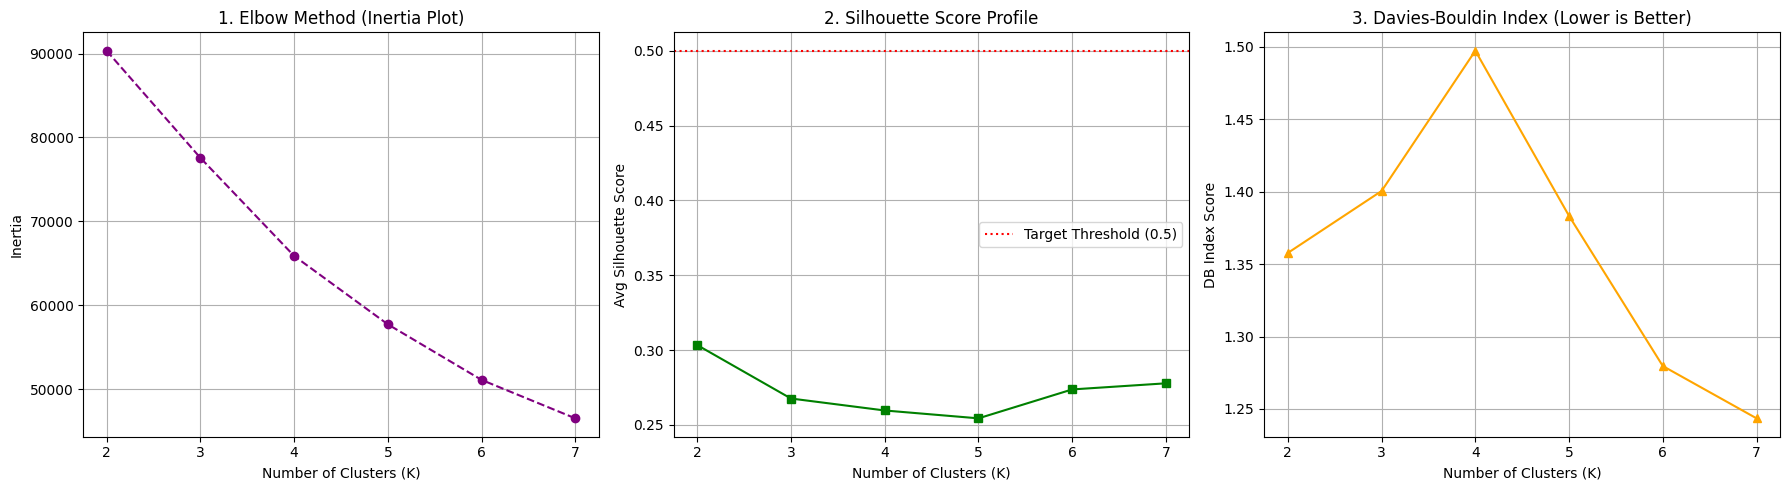

In [12]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import PowerTransformer

# ==========================================
# 1. SETUP CLUSTERING DATA (Example Slice)
# ==========================================
features = [
    'impressions_90d', 'clicks_90d', 'ctr', 'avg_position', 
    'word_count', 'content_age_days'
]

# Extract numeric clustering slice and drop rows with missing values
X_raw = df[features].dropna()

# Apply the Yeo-Johnson transform to handle heavy right-skewed SEO data
scaler = PowerTransformer(method='yeo-johnson')
X_scaled = scaler.fit_transform(X_raw)

# ==============================================
# 2. RUN METRIC LOOP FOR CHOSEN CLUSTER K-RANGE
# ==============================================
inertia_scores = []
silhouette_scores = []
davies_bouldin_scores = []

k_range = range(2, 8)  # Checking a cluster spectrum of 2 to 7

print("Evaluating cluster metrics across range...")
for k in k_range:
    # Initialize K-Means with deterministic seed
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    # 📉 Elbow Method Metric (Sum of squared distances)
    inertia_scores.append(kmeans.inertia_)
    
    # 🌟 Internal Evaluation Metrics
    sil_avg = silhouette_score(X_scaled, cluster_labels)
    db_idx = davies_bouldin_score(X_scaled, cluster_labels)
    
    silhouette_scores.append(sil_avg)
    davies_bouldin_scores.append(db_idx)
    
    print(f"K={k} | Silhouette Score: {sil_avg:.4f} (Aiming > 0.5) | Davies-Bouldin: {db_idx:.4f} (Aiming lower)")

# ==========================================
# 3. PLOT THE STRUCTURAL REFLECTION METRICS
# ==========================================
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: The Elbow Method (Inertia)
axs[0].plot(k_range, inertia_scores, marker='o', color='purple', linestyle='--')
axs[0].set_title('1. Elbow Method (Inertia Plot)')
axs[0].set_xlabel('Number of Clusters (K)')
axs[0].set_ylabel('Inertia')
axs[0].grid(True)

# Plot 2: Silhouette Score Plot
axs[1].plot(k_range, silhouette_scores, marker='s', color='green', linestyle='-')
axs[1].axhline(y=0.5, color='r', linestyle=':', label='Target Threshold (0.5)')
axs[1].set_title('2. Silhouette Score Profile')
axs[1].set_xlabel('Number of Clusters (K)')
axs[1].set_ylabel('Avg Silhouette Score')
axs[1].legend()
axs[1].grid(True)

# Plot 3: Davies-Bouldin Index Plot
axs[2].plot(k_range, davies_bouldin_scores, marker='^', color='orange', linestyle='-')
axs[2].set_title('3. Davies-Bouldin Index (Lower is Better)')
axs[2].set_xlabel('Number of Clusters (K)')
axs[2].set_ylabel('DB Index Score')
axs[2].grid(True)

plt.tight_layout()
plt.show()

For Lane 3, I engineered a dual-stage unsupervised pipeline. I'll first deploy `DBSCAN` to leverage its density-based mechanics to cleanly isolate erratic, low-density outliers—directly mapping them to our *Weak/No-Demand* business archetype. I'll then route the filtered, clean distribution matrix into `KMeans`. This strategy guarantees that our core archetype clusters—like *Champions* and *Stale Visible Pages* —form tight, high-silhouette groupings with **stable**, **unskewed** baseline averages.

Below is the example code to give a simplistic demo. I did it deliberately on a subset of numeric only features, and without the parameter tuning, but the final code will be more robust and will include all the features and parameter tuning.

In [ ]:
import numpy as np
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import PowerTransformer

# ===================================================
# STEP 1: INITIAL DATA SANITIZATION & TRANSFORMATION
# ===================================================
X_raw = df.drop(columns=['content_id', 'client_id', 'trend_direction', 'trend_pct'], errors='ignore')

# Keep only continuous numeric columns for geometrical vector operations
X_numeric = X_raw.select_dtypes(include=[np.number]).dropna()

# Normalize heavy search engine skews using the Yeo-Johnson engine
scaler = PowerTransformer(method='yeo-johnson')
X_scaled = scaler.fit_transform(X_numeric)

# Make a clean dataframe tracker to store our step-by-step labels
df_results = X_numeric.copy()

# =====================================================
# STEP 2: PHASE 1 — DEPLOY DBSCAN AS AN OUTLIER SHIELD
# =====================================================
# Configure density thresholds to isolate low-density anomalies
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Store the raw DBSCAN labels (-1 means noise/weak pages)
df_results['DBSCAN_Raw'] = dbscan_labels

# Create a logical mask to isolate only the stable, dense core records
core_mask = dbscan_labels != -1

# Extract the filtered data matrices for the next stage
X_scaled_clean = X_scaled[core_mask]
df_results_clean = df_results[core_mask].copy()

print(f"Total Rows: {len(X_scaled)}")
print(f"Isolated Noise Outliers (Weak Pages): {list(dbscan_labels).count(-1)}")
print(f"Clean Core Rows routed to K-Means: {len(X_scaled_clean)}")

# ==========================================================
# STEP 3: PHASE 2 — DEPLOY K-MEANS ON CLEAN ARCHETYPES ONLY
# ==========================================================
# Initialize K-Means with deterministic random seeding to cluster clean data
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled_clean)

# Assign K-Means clusters to the clean dataframe slice
df_results_clean['KMeans_Archetype'] = kmeans_labels

# ========================================================
# STEP 4: RE-ALIGN CLUSTERS INTO ONE UNIFIED PRODUCTION DF
# ========================================================
# Initialize the final archetype column as a string
df_results['Final_Archetype'] = "Weak / No-Demand Page (Noise)"

# Re-map the clean K-Means cluster IDs back to their respective non-noise rows
# Converting numerical cluster tags to concrete business profile titles
archetype_mapping = {
    0: "Stale Visible Page",
    1: "Hidden Gem",
    2: "Champion Content",
    3: "Rising Star"
}

df_results.loc[core_mask, 'Final_Archetype'] = [archetype_mapping[label] for label in kmeans_labels]

print("\n--- Final Unified Production Archetype Segmentation Matrix ---")
print(df_results['Final_Archetype'].value_counts())

Total Rows: 19897
Isolated Noise Outliers (Weak Pages): 19735
Clean Core Rows routed to K-Means: 162

--- Final Unified Production Archetype Segmentation Matrix ---
Final_Archetype
Weak / No-Demand Page (Noise)    19735
Hidden Gem                          71
Stale Visible Page                  40
Rising Star                         39
Champion Content                    12
Name: count, dtype: int64


## 4. The unit of analysis, as a real dataframe

*Load your lane's slice and show it: one row = one what?*

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import pandas as pd
import json

raw_data_dir = '../../data/raw/content_refresh_anonymized.csv'

df = pd.read_csv(raw_data_dir)
df.drop(columns = ['content_id', 'client_id', 'trend_direction', 'trend_pct'], inplace = True)

print(json.dumps(df.head(1).to_dict(), indent=4))
print(f"Dataframe shape: {df.shape}")

{
    "search_volume": {
        "0": 10.0
    },
    "competition": {
        "0": 0.67
    },
    "competition_level": {
        "0": "HIGH"
    },
    "cpc": {
        "0": 2.05
    },
    "content_type": {
        "0": "keyword article"
    },
    "main_intent": {
        "0": "transactional"
    },
    "word_count": {
        "0": 3221.0
    },
    "char_count": {
        "0": 20457.0
    },
    "provider_used": {
        "0": NaN
    },
    "model_used": {
        "0": "gemini-2.5-flash"
    },
    "impressions_90d": {
        "0": 3803
    },
    "clicks_90d": {
        "0": 29
    },
    "pageviews_90d": {
        "0": 22
    },
    "sessions_90d": {
        "0": 17
    },
    "users_90d": {
        "0": 16
    },
    "engaged_sessions_90d": {
        "0": 1
    },
    "ai_sessions_90d": {
        "0": 0
    },
    "scroll_events_90d": {
        "0": 1
    },
    "days_with_impressions": {
        "0": 88
    },
    "days_with_sessions": {
        "0": 13
    },
    "impression

In this processed analysis dataframe, one row represents an anonymized, multi-dimensional behavioral and structural footprint of a single content asset.

Because the explicit text entities (`content_id`), site groupings (`client_id`), and leakage causing columns (`trend_direction`, `trend_pct`) have been stripped away, the rows are treated strictly as a collection of coordinate metrics within a continuous feature space.

The single row in my analysis dataframe tells about the entire business and SEO related characteristics of the page.

## 5. Why ML beats a fixed rule here

*What makes the pattern too messy for an if-statement?*

The simple reason for not going for the `if-else` route is because the data is highly varying in its nature. Specifically, in the SEO domain, no pattern remains the constant for a long time and exhibits the same behaviour across different search engines, and the data is highly dynamic in nature due to its inherent variability. Hence, it is not possible to create a fixed rule for this problem statement. The clustering algorithm will be able to find the patterns in the data and group them accordingly, which will be more effective than a fixed rule.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.